# 05 · Modelling and validation: the chosen segmentation (seg-v1.0)

**Phase 3 deliverables:** model notebook (this one), **validation report including the adjusted Rand index**, and the **chosen segmentation**.

Steps, as in the plan:
1. **k-means baseline** on the numeric features.
2. **k-prototypes** on the full mixed feature set for k = 2 to 10, with **Gower distance and hierarchical clustering as a cross-check**.
3. Choose k from the **elbow curve, silhouette score and business readability** together (2-3 candidates presented).
4. **Stability:** refit on **20 bootstrap samples** and compare with the reference fit (adjusted Rand index, ARI).
5. **Held-out outcomes:** do segments differ on conversion, revenue and late payment? (never used to build them)
6. Name the segments from their profiles, save the labels and load them into `clean.ds_labels_staging` (Day 10, file 9 STEP 1).
7. **After the team commits:** the project lead scores the segments against the answer key (`true_persona`) with the ARI.

Every run is tracked in **MLflow** (database `mlflow.db` in the project folder; open with `mlflow ui --backend-store-uri sqlite:///mlflow.db`), if MLflow is installed.
Runtime: about 8-12 minutes on a laptop (k-prototypes is fitted on samples, then every customer is assigned).

**Outputs** (folder `reports/05_model/`): `customer_segments_seg-v1.0.csv`, `Veltrix_validation_report.docx`, charts, `model_selection.csv`.

In [1]:
# First time only:  %pip install kmodes scikit-learn scipy mlflow python-docx openpyxl sqlalchemy psycopg2-binary

In [2]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score as ARI
from kmodes.kprototypes import KPrototypes
from IPython.display import display, Markdown
import vx

warnings.filterwarnings("ignore")
vx.connect()
vx.style()
OUT = vx.out_dir("05_model")
CH = OUT / "charts"
say = lambda s: display(Markdown(s))

SEED = 42
N_FIT = 8000        # sample for the k search (k-prototypes is slow on 100k rows)
N_EVAL = 3000       # sample for silhouette / Gower / hierarchical checks
N_BOOT = 20         # bootstrap refits per candidate
N_FINAL = 20000     # sample for the final fit; every customer is then assigned
GAMMA = 1.0         # weight of a categorical mismatch = one standard deviation on a numeric feature
K_RANGE = range(2, 11)
READABLE = range(5, 10)   # business readability: 5-9 segments (the plan targets 6-8)

Connected to database 'Veltrix' on localhost:5432 as postgres


In [3]:
try:
    import mlflow
    mlflow.set_tracking_uri("sqlite:///" + (vx.ROOT / "mlflow.db").as_posix())   # view: mlflow ui --backend-store-uri sqlite:///mlflow.db
    mlflow.set_experiment("veltrix-segmentation")
    MLF = True
except Exception as e:      # MLflow is optional: the notebook runs without it
    print("MLflow not available, runs are not tracked:", e)
    MLF = False

def track(name, params, metrics):
    if not MLF:
        return
    try:
        with mlflow.start_run(run_name=name):
            mlflow.log_params(params)
            mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
    except Exception as e:
        print("MLflow logging skipped:", e)

## 1. The model inputs (from notebook 04)

In [4]:
spec = json.load(open(vx.REPORTS / "04_features" / "feature_spec.json"))
NUM = ["z_" + c for c in spec["numeric"]]
CAT = spec["categorical"]
m = vx.Q("SELECT * FROM feat.customer_features_model ORDER BY customer_id")
X = pd.concat([m[NUM].astype(float), m[CAT].astype(str)], axis=1)
CI = list(range(len(NUM), len(NUM) + len(CAT)))
XA = X.to_numpy(dtype=object)
fit_idx = X.sample(N_FIT, random_state=SEED).index
ev_idx = X.sample(N_EVAL, random_state=SEED + 1).index
say(f"**{len(X):,} customers**, {len(NUM)} numeric features (scaled) and {len(CAT)} categorical: {', '.join(CAT)}.")

def gower(num, cat):
    """Gower distance matrix: numeric |a-b| / range, categorical mismatch 0/1, averaged over features."""
    num = np.asarray(num, float)
    rng = num.max(0) - num.min(0)
    rng[rng == 0] = 1
    D = np.zeros((len(num), len(num)))
    for j in range(num.shape[1]):
        D += np.abs(num[:, j, None] - num[None, :, j]) / rng[j]
    cat = np.asarray(cat)
    for j in range(cat.shape[1]):
        D += cat[:, j, None] != cat[None, :, j]
    return D / (num.shape[1] + cat.shape[1])

G = gower(X.loc[ev_idx, NUM], X.loc[ev_idx, CAT])

**100,573 customers**, 10 numeric features (scaled) and 8 categorical: preferred_region, preferred_property_type, lead_source_primary, finance_type, customer_type, is_overseas, buyer_position, age_band.

## 2. Baseline: k-means on the numeric features only

In [5]:
km_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=4, random_state=SEED).fit(X[NUM])
    sil = silhouette_score(X.loc[ev_idx, NUM], km.predict(X.loc[ev_idx, NUM]))
    km_rows.append(dict(k=k, inertia=km.inertia_, silhouette=sil))
    track(f"kmeans_k{k}", dict(model="kmeans", k=k, features="numeric"), dict(inertia=km.inertia_, silhouette=sil))
km_res = pd.DataFrame(km_rows)
km_res.round(3)

,k,inertia,silhouette
0,2,787864.428,0.319
1,3,643084.527,0.358
2,4,575789.834,0.200
3,5,537019.445,0.198
4,6,494311.340,0.199
5,7,475009.380,0.193
6,8,436286.068,0.204
7,9,414270.529,0.215
8,10,399774.932,0.221


## 3. k-prototypes on the mixed features, k = 2 to 10

In [6]:
def fit_kp(k, idx, n_init=3, seed=SEED):
    kp = KPrototypes(n_clusters=k, init="Cao", n_init=n_init, random_state=seed, gamma=GAMMA, max_iter=50)
    kp.fit(XA[X.index.get_indexer(idx)], categorical=CI)
    return kp

kp_rows, models = [], {}
for k in K_RANGE:
    t0 = time.time()
    kp = fit_kp(k, fit_idx)
    lab_ev = kp.predict(XA[X.index.get_indexer(ev_idx)], categorical=CI)
    sil = silhouette_score(G, lab_ev, metric="precomputed") if len(set(lab_ev)) > 1 else np.nan
    sizes = np.bincount(kp.labels_, minlength=k) / N_FIT
    models[k] = kp
    kp_rows.append(dict(k=k, cost=kp.cost_, silhouette_gower=sil, smallest_segment_pct=100 * sizes.min(), seconds=time.time() - t0))
    track(f"kprototypes_k{k}", dict(model="kprototypes", k=k, gamma=GAMMA, n_fit=N_FIT, init="Cao"),
          dict(cost=kp.cost_, silhouette_gower=sil, smallest_segment_pct=100 * sizes.min()))
    print(f"k={k}: cost {kp.cost_:,.0f}  silhouette (Gower) {sil:.3f}  smallest segment {100 * sizes.min():.1f}%  ({time.time() - t0:.0f}s)")
kp_res = pd.DataFrame(kp_rows)

k=2: cost 92,005  silhouette (Gower) 0.279  smallest segment 21.0%  (6s)
k=3: cost 79,781  silhouette (Gower) 0.294  smallest segment 7.0%  (11s)
k=4: cost 72,991  silhouette (Gower) 0.190  smallest segment 6.9%  (11s)
k=5: cost 69,700  silhouette (Gower) 0.172  smallest segment 6.8%  (11s)
k=6: cost 66,319  silhouette (Gower) 0.197  smallest segment 6.8%  (7s)
k=7: cost 62,333  silhouette (Gower) 0.130  smallest segment 5.8%  (14s)
k=8: cost 60,249  silhouette (Gower) 0.144  smallest segment 5.5%  (12s)
k=9: cost 58,670  silhouette (Gower) 0.148  smallest segment 4.8%  (12s)
k=10: cost 56,573  silhouette (Gower) 0.144  smallest segment 1.8%  (12s)


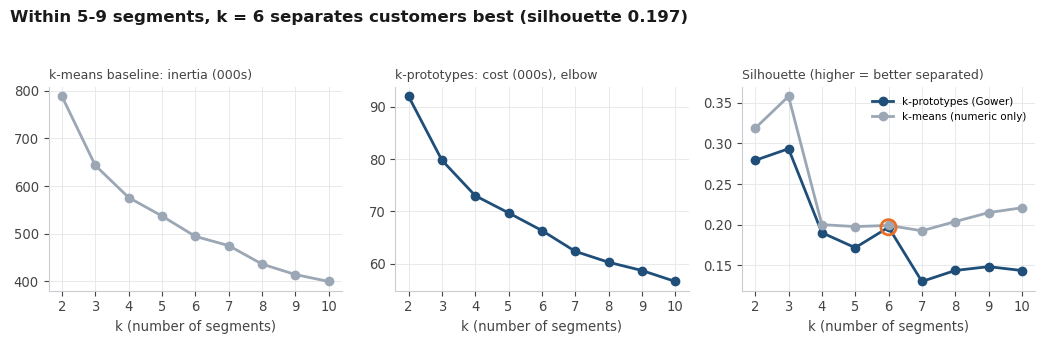

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
axes[0].plot(km_res.k, km_res.inertia / 1e3, marker="o", color=vx.GREY, lw=2)
axes[0].set_title("k-means baseline: inertia (000s)", loc="left", fontsize=9, color=vx.INK2)
axes[1].plot(kp_res.k, kp_res.cost / 1e3, marker="o", color=vx.NAVY, lw=2)
axes[1].set_title("k-prototypes: cost (000s), elbow", loc="left", fontsize=9, color=vx.INK2)
axes[2].plot(kp_res.k, kp_res.silhouette_gower, marker="o", color=vx.NAVY, lw=2, label="k-prototypes (Gower)")
axes[2].plot(km_res.k, km_res.silhouette, marker="o", color=vx.GREY, lw=2, label="k-means (numeric only)")
best = kp_res[kp_res.k.isin(READABLE)].sort_values("silhouette_gower", ascending=False).iloc[0]
axes[2].scatter([best.k], [best.silhouette_gower], s=120, facecolor="none", edgecolor=vx.ORANGE, lw=2, zorder=5)
axes[2].set_title("Silhouette (higher = better separated)", loc="left", fontsize=9, color=vx.INK2)
axes[2].legend(fontsize=7.5)
for a in axes:
    a.set_xticks(list(K_RANGE))
    a.set_xlabel("k (number of segments)")
p_sel = vx.finish(fig, axes[0], f"Within 5-9 segments, k = {int(best.k)} separates customers best (silhouette {best.silhouette_gower:.3f})", "",
                  CH / "01_model_selection.png")

## 4. Cross-check: hierarchical clustering on Gower distance

In [8]:
Z = linkage(squareform(G, checks=False), method="average")
hc_rows = []
for k in READABLE:
    hc = fcluster(Z, k, criterion="maxclust")
    kp_ev = models[k].predict(XA[X.index.get_indexer(ev_idx)], categorical=CI)
    hc_rows.append(dict(k=k, ari_kprototypes_vs_hierarchical=ARI(kp_ev, hc)))
hc_res = pd.DataFrame(hc_rows)
kp_res = kp_res.merge(hc_res, on="k", how="left")
hc_res.round(3)

,k,ari_kprototypes_vs_hierarchical
0,5,0.335
1,6,0.397
2,7,0.387
3,8,0.395
4,9,0.381


## 5. Candidates and bootstrap stability (20 refits each)

In [9]:
cands = kp_res[kp_res.k.isin(READABLE)].sort_values("silhouette_gower", ascending=False).head(3).k.astype(int).tolist()
ev_pos = X.index.get_indexer(ev_idx)
stab = {}
rng = np.random.default_rng(SEED)
for k in cands:
    ref = models[k].predict(XA[ev_pos], categorical=CI)
    scores = []
    t0 = time.time()
    for b in range(N_BOOT):
        idx = X.index[rng.choice(len(X), size=5000, replace=True)]
        kb = fit_kp(k, idx, n_init=2, seed=SEED + b)
        scores.append(ARI(ref, kb.predict(XA[ev_pos], categorical=CI)))
    stab[k] = scores
    track(f"bootstrap_k{k}", dict(model="kprototypes", k=k, n_boot=N_BOOT, boot_size=5000),
          dict(stability_mean_ari=np.mean(scores), stability_min_ari=np.min(scores)))
    print(f"k={k}: bootstrap ARI mean {np.mean(scores):.3f}, min {np.min(scores):.3f} ({time.time() - t0:.0f}s)")
cand = kp_res[kp_res.k.isin(cands)].copy()
cand["stability_mean_ari"] = cand.k.map(lambda k: np.mean(stab[k]))
cand["stability_p10_ari"] = cand.k.map(lambda k: np.percentile(stab[k], 10))
cand = cand.sort_values("silhouette_gower", ascending=False)
cand.round(3)

k=6: bootstrap ARI mean 0.658, min 0.433 (80s)
k=5: bootstrap ARI mean 0.541, min 0.491 (75s)
k=9: bootstrap ARI mean 0.629, min 0.465 (93s)


,k,cost,silhouette_gower,smallest_segment_pct,seconds,ari_kprototypes_vs_hierarchical,stability_mean_ari,stability_p10_ari
4,6,66318.530,0.197,6.825,7.065,0.397,0.658,0.616
3,5,69699.730,0.172,6.825,10.728,0.335,0.541,0.493
7,9,58670.285,0.148,4.775,12.143,0.381,0.629,0.509


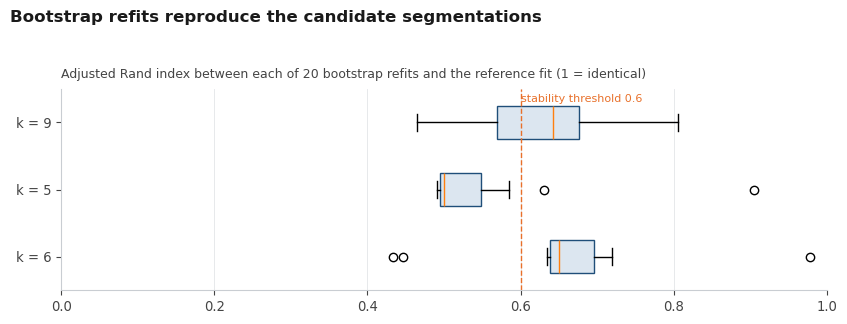

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
bp = ax.boxplot([stab[k] for k in cand.k], vert=False, widths=0.5, patch_artist=True,
                tick_labels=[f"k = {k}" for k in cand.k])
for patch in bp["boxes"]:
    patch.set_facecolor("#DCE6F0")
    patch.set_edgecolor(vx.NAVY)
ax.axvline(0.6, color=vx.ORANGE, ls="--", lw=1)
ax.annotate("stability threshold 0.6", (0.6, len(cand) + 0.3), fontsize=8, color=vx.ORANGE)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
p_stab = vx.finish(fig, ax, "Bootstrap refits reproduce the candidate segmentations",
                   f"Adjusted Rand index between each of {N_BOOT} bootstrap refits and the reference fit (1 = identical)", CH / "02_stability.png")

## 6. Choose k
Rule: among the candidates whose mean bootstrap ARI is at least 0.6 (stable), take the best silhouette. Set `CHOSEN_K` by hand to override after discussing with the business.

In [11]:
CHOSEN_K = None
stable = cand[cand.stability_mean_ari >= 0.6]
chosen = int(CHOSEN_K or (stable.iloc[0].k if len(stable) else cand.sort_values("stability_mean_ari").iloc[-1].k))
crow = cand.set_index("k").loc[chosen]
say(f"**Chosen: k = {chosen}** (silhouette {crow.silhouette_gower:.3f}, bootstrap ARI {crow.stability_mean_ari:.2f}, "
    f"smallest segment {crow.smallest_segment_pct:.1f}% of customers).")

**Chosen: k = 6** (silhouette 0.197, bootstrap ARI 0.66, smallest segment 6.8% of customers).

## 7. Final fit and assignment of every customer

In [12]:
final_idx = X.sample(N_FINAL, random_state=SEED + 2).index
t0 = time.time()
final = fit_kp(chosen, final_idx, n_init=5)
labels = final.predict(XA, categorical=CI)
print(f"Final fit on {N_FINAL:,} customers in {time.time() - t0:.0f}s; segment sizes:", np.bincount(labels))
track(f"final_k{chosen}", dict(model="kprototypes", k=chosen, gamma=GAMMA, n_fit=N_FINAL, model_version="seg-v1.0"),
      dict(cost=final.cost_, silhouette_gower=crow.silhouette_gower, stability_mean_ari=crow.stability_mean_ari))

Final fit on 20,000 customers in 45s; segment sizes: [23919 20263 27206 15563  7418  6204]


## 8. Profiles and names
Names come from each segment's profile (rules below), never from the answer key. Edit `NAMES_OVERRIDE` if the business prefers other wording.

In [13]:
prof_src = vx.Q("""SELECT c.customer_id, c.customer_type, c.primary_intent, c.is_overseas, c.buyer_position, c.age_band,
                          c.finance_type, f.budget_gbp_imputed, f.rent_budget_pcm_imputed, f.sessions_total, f.enquiries_total,
                          f.night_session_share, f.virtual_tour_share, f.mobile_share, f.new_build_share, f.london_share
                   FROM clean.clean_customers c JOIN feat.customer_features_model f USING (customer_id) ORDER BY c.customer_id""")
prof_src["seg"] = labels
P = prof_src.groupby("seg").agg(
    customers=("customer_id", "size"), overseas=("is_overseas", "mean"),
    corporate=("customer_type", lambda s: (s == "Corporate").mean()), spv=("customer_type", lambda s: (s == "Limited company (SPV)").mean()),
    renters=("primary_intent", lambda s: (s == "Rent").mean()), no_lead=("enquiries_total", lambda s: (s == 0).mean()),
    ftb=("buyer_position", lambda s: s.str.startswith("First-time").mean()),
    mover=("buyer_position", lambda s: s.str.startswith("Home mover").mean()),
    downsizer=("buyer_position", lambda s: s.str.startswith("Downsizer").mean()),
    landlord=("buyer_position", lambda s: s.str.contains("landlord|investor", case=False).mean()),
    btl=("finance_type", lambda s: (s == "Buy-to-let mortgage").mean()),
    cash=("finance_type", lambda s: (s == "Cash").mean()), age55=("age_band", lambda s: s.isin(["55-64", "65+"]).mean()),
    budget=("budget_gbp_imputed", "median"), rent=("rent_budget_pcm_imputed", "median"), sessions=("sessions_total", "median"),
    night=("night_session_share", "mean"), tours=("virtual_tour_share", "mean"), mobile=("mobile_share", "mean"),
    london=("london_share", "mean"))

def name_of(r):
    if r.overseas > 0.5:
        return "Overseas investors"
    if r.corporate > 0.5:
        return "Corporate relocation tenants"
    if r.no_lead > 0.6:
        return "Window shoppers"
    if r.renters > 0.6:
        return "Young renters" if r.mobile > 0.7 else "Renters"
    if r.landlord > 0.4 or r.spv > 0.4 or r.btl > 0.4:
        return "Buy-to-let investors"
    if r.downsizer > 0.4 or (r.age55 > 0.5 and r.cash > 0.4):
        return "Downsizers"
    if r.ftb > 0.4:
        return "First-time buyers"
    if r.mover > 0.4:
        return "Home movers"
    return "Mixed buyers"

names = P.apply(name_of, axis=1)
for nm in names[names.duplicated(keep=False)].unique():     # make duplicate names distinct by price level
    ids = names[names == nm].index
    order = P.loc[ids, "budget"].fillna(P.loc[ids, "rent"]).sort_values().index
    for i, sid in enumerate(order):
        names[sid] = f"{nm} ({'lower' if i == 0 else 'higher' if i == len(order) - 1 else 'mid'} budget)"
NAMES_OVERRIDE = {}          # e.g. {3: "Family home movers"}
names.update(pd.Series(NAMES_OVERRIDE, dtype=object))
P.insert(0, "segment_name", names)
P["pct_customers"] = 100 * P.customers / P.customers.sum()
show = P[["segment_name", "customers", "pct_customers", "renters", "overseas", "no_lead", "budget", "rent", "night", "tours", "mobile"]].copy()
show.round(2)

,segment_name,customers,pct_customers,renters,overseas,no_lead,budget,rent,night,tours,mobile
seg,,,,,,,,,,,
0,Home movers,23919,23.78,0.00,0.02,0.53,425000.0,NaN,0.03,0.04,0.37
1,Renters,20263,20.15,1.00,0.07,0.43,NaN,1500.0,0.04,0.04,0.69
2,First-time buyers,27206,27.05,0.00,0.01,0.40,255000.0,NaN,0.03,0.03,0.79
3,Buy-to-let investors,15563,15.47,0.00,0.05,0.01,220000.0,1800.0,0.03,0.04,0.27
4,Overseas investors,7418,7.38,0.04,0.88,0.38,580000.0,3000.0,0.25,0.21,0.54
5,Window shoppers,6204,6.17,0.05,0.03,0.81,340000.0,1325.0,0.03,0.03,0.63


## 9. Held-out outcomes: do the segments differ on conversion, revenue and late payment?
Outcomes were never model inputs. Tests: chi-square for conversion and late payment, Kruskal-Wallis for deal value per customer.

In [14]:
oc = vx.Q("""SELECT customer_id, n_closed_leads, n_won_leads, deal_value_gbp, payments_due, payments_late_or_overdue
             FROM feat.customer_outcomes ORDER BY customer_id""")
oc = prof_src[["customer_id", "seg"]].merge(oc, on="customer_id", how="left").fillna(0)
O = oc.groupby("seg").agg(closed=("n_closed_leads", "sum"), won=("n_won_leads", "sum"), value=("deal_value_gbp", "sum"),
                          due=("payments_due", "sum"), late=("payments_late_or_overdue", "sum"), customers=("customer_id", "size"))
O["conversion_pct"] = 100 * O.won / O.closed
O["deal_value_per_customer"] = O.value / O.customers
O["pct_of_deal_value"] = 100 * O.value / O.value.sum()
O["late_pct"] = 100 * O.late / O.due
O.insert(0, "segment_name", names)
chi_conv = stats.chi2_contingency(np.c_[O.won, O.closed - O.won])
chi_late = stats.chi2_contingency(np.c_[O.late, O.due - O.late])
kw = stats.kruskal(*[g.deal_value_gbp.values for _, g in oc.groupby("seg")])
tests = pd.DataFrame([["Conversion (won / closed leads)", "chi-square", chi_conv[0], chi_conv[1]],
                      ["Late payment (late / payments due)", "chi-square", chi_late[0], chi_late[1]],
                      ["Deal value per customer", "Kruskal-Wallis", kw.statistic, kw.pvalue]],
                     columns=["Outcome", "Test", "Statistic", "p-value"])
display(O[["segment_name", "customers", "conversion_pct", "deal_value_per_customer", "pct_of_deal_value", "late_pct"]].round(1))
tests

,segment_name,customers,conversion_pct,deal_value_per_customer,pct_of_deal_value,late_pct
seg,,,,,,
0,Home movers,23919,17.1,35533.0,21.0,3.4
1,Renters,20263,27.3,5546.4,2.8,9.2
2,First-time buyers,27206,12.6,32034.4,21.5,3.5
3,Buy-to-let investors,15563,19.2,114445.8,44.0,3.1
4,Overseas investors,7418,14.1,54055.1,9.9,5.5
5,Window shoppers,6204,7.1,5279.2,0.8,2.3


,Outcome,Test,Statistic,p-value
0,Conversion (won / closed leads),chi-square,1604.712201,0.000000e+00
1,Late payment (late / payments due),chi-square,965.707786,1.594610e-206
2,Deal value per customer,Kruskal-Wallis,6866.807806,0.000000e+00


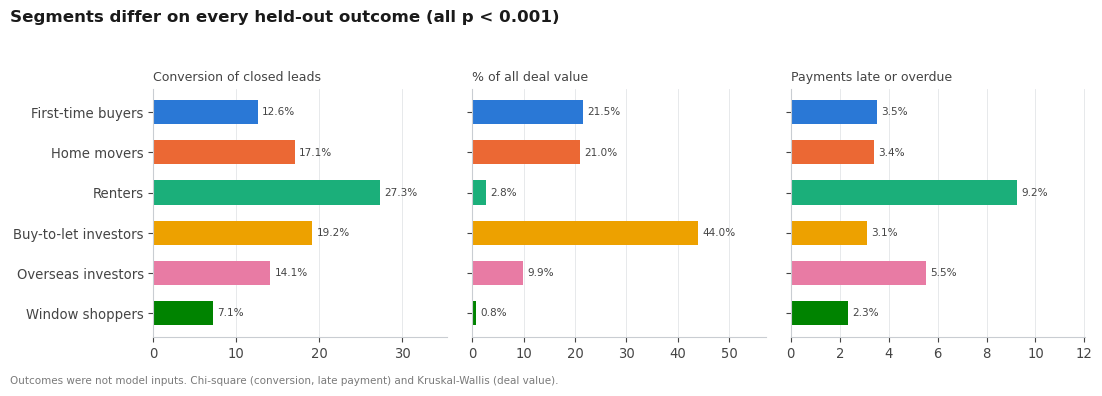

In [15]:
ordr = O.sort_values("customers", ascending=False).index
cols = {s: vx.SERIES[i % 8] for i, s in enumerate(ordr)}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for a, col, ttl, fmt in [(axes[0], "conversion_pct", "Conversion of closed leads", "{:.1f}%"),
                         (axes[1], "pct_of_deal_value", "% of all deal value", "{:.1f}%"),
                         (axes[2], "late_pct", "Payments late or overdue", "{:.1f}%")]:
    d = O.loc[ordr[::-1]]
    b = a.barh(d.segment_name, d[col], color=[cols[s] for s in d.index], height=0.6)
    vx.barh_labels(a, b, fmt, size=7.5)
    a.set_title(ttl, loc="left", fontsize=9, color=vx.INK2)
    a.set_xlim(0, d[col].max() * 1.3)
    a.grid(axis="y", visible=False)
top_v = O.sort_values("pct_of_deal_value").iloc[-1]
p_out = vx.finish(fig, axes[0], f"Segments differ on every held-out outcome (all p < 0.001)" if tests["p-value"].max() < 0.001
                  else "Segments differ on held-out outcomes", "", CH / "03_outcomes.png",
                  note="Outcomes were not model inputs. Chi-square (conversion, late payment) and Kruskal-Wallis (deal value).")

## 10. Save the chosen segmentation and load it into the database (Day 10, file 9 STEP 1)

In [16]:
seg_id = {s: i + 1 for i, s in enumerate(ordr)}            # 1 = largest segment
out = pd.DataFrame({"customer_id": m.customer_id, "segment_id": [seg_id[s] for s in labels],
                    "segment_name": [names[s] for s in labels]})
out.to_csv(OUT / "customer_segments_seg-v1.0.csv", index=False)
kp_res.merge(cand[["k", "stability_mean_ari", "stability_p10_ari"]], on="k", how="left").to_csv(OUT / "model_selection.csv", index=False)
LOAD_TO_STAGING = True
if LOAD_TO_STAGING:
    vx.run("TRUNCATE clean.ds_labels_staging")
    out.to_sql("ds_labels_staging", vx.ENGINE, schema="clean", if_exists="append", index=False, chunksize=10000, method="multi")
    say(f"Loaded **{len(out):,} rows** into `clean.ds_labels_staging`. Next, in pgAdmin, run **week2/9_validation_and_swap.sql "
        f"STEP 1c and 1d** (copies them in as seg-v1.0), **STEP 2** (tests), **STEP 3** (switch the dashboard), then re-run Week 3 files 10-14 "
        f"and refresh Power BI.")
out.segment_name.value_counts()

Loaded **100,573 rows** into `clean.ds_labels_staging`. Next, in pgAdmin, run **week2/9_validation_and_swap.sql STEP 1c and 1d** (copies them in as seg-v1.0), **STEP 2** (tests), **STEP 3** (switch the dashboard), then re-run Week 3 files 10-14 and refresh Power BI.

segment_name
First-time buyers       27206
Home movers             23919
Renters                 20263
Buy-to-let investors    15563
Overseas investors       7418
Window shoppers          6204
Name: count, dtype: int64

## 11. PROJECT LEAD ONLY, after the team commits: adjusted Rand index against the answer key
The answer key was never used above. Here, and only here, `true_persona` is read to score the committed segmentation.

In [17]:
score = None
if vx.ANSWER_KEY.exists():
    key = pd.read_parquet(vx.ANSWER_KEY, columns=["customer_id", "true_persona"]).set_index("customer_id").true_persona
    truth = m.customer_id.map(key)
    km_final = KMeans(n_clusters=chosen, n_init=4, random_state=SEED).fit_predict(X[NUM])
    score = dict(ari_final=ARI(truth, labels), ari_kmeans=ARI(truth, km_final),
                 by_k={k: ARI(truth, models[k].predict(XA, categorical=CI)) for k in cands})
    track("answer_key_score", dict(k=chosen, model_version="seg-v1.0"), dict(ari_true_persona=score["ari_final"], ari_kmeans_baseline=score["ari_kmeans"]))
    ct = pd.crosstab(pd.Series([names[s] for s in labels], name="segment"), truth.rename("true persona"), normalize="index") * 100
    say(f"**ARI against true personas: {score['ari_final']:.3f}** (k-means baseline on numeric features: {score['ari_kmeans']:.3f}; "
        f"0 = random, 1 = perfect). Candidates: " + ", ".join(f"k={k}: {v:.3f}" for k, v in score["by_k"].items()) + ".")
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(ct.shape[1]), [c.replace("_", " ") for c in ct.columns], rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(ct.shape[0]), ct.index, fontsize=8)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            v = ct.values[i, j]
            if v >= 5:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v > 55 else vx.INK)
    ax.grid(False)
    p_key = vx.finish(fig, ax, f"Segments recover the hidden personas with ARI {score['ari_final']:.2f}",
                      "% of each segment's customers by true persona (answer key, read after the model was committed)",
                      CH / "04_answer_key.png")
else:
    say("Answer key not available: this step is for the project lead after Phase 4 starts.")

Answer key not available: this step is for the project lead after Phase 4 starts.

## 12. Validation report (Word)

In [18]:
r = vx.Report("Validation report", "Phase 3 · Modelling and validation · segmentation seg-v1.0",
              "k-prototypes on feat.customer_features_model · generated by notebooks/05_model_and_validation.ipynb")
r.h1("Summary")
kp_list = [(f"{chosen}", "segments chosen"), (f"{crow.silhouette_gower:.3f}", "silhouette (Gower)"),
           (f"{crow.stability_mean_ari:.2f}", f"bootstrap ARI ({N_BOOT} refits)")]
if score:
    kp_list.append((f"{score['ari_final']:.2f}", "ARI vs true personas"))
r.kpis(kp_list)
r.bullets([f"**Model:** k-prototypes (numeric and categorical features together), Cao initialisation, categorical weight gamma = {GAMMA}; "
           f"k-means on the numeric features as the baseline; hierarchical clustering on Gower distance as a cross-check.",
           f"**Choice of k:** candidates {', '.join(map(str, cand.k))} were the best-separated solutions with 5-9 segments. "
           f"k = {chosen} has the best silhouette among the stable ones and gives segments the business can name and act on.",
           f"**Stable:** {N_BOOT} bootstrap refits reproduce the segmentation with a mean adjusted Rand index of {crow.stability_mean_ari:.2f}.",
           f"**Useful:** the segments differ on outcomes the model never saw: conversion from {O.conversion_pct.min():.1f}% to "
           f"{O.conversion_pct.max():.1f}%, late payment from {O.late_pct.min():.1f}% to {O.late_pct.max():.1f}%, and "
           f"{top_v.segment_name} alone brings {top_v.pct_of_deal_value:.0f}% of deal value."]
          + ([f"**Scored against the answer key** (after the commit): ARI {score['ari_final']:.2f} against the hidden personas, against "
              f"{score['ari_kmeans']:.2f} for the k-means baseline."] if score else []))
r.h1("1. Data and features")
r.p(f"{len(X):,} customers; {len(NUM)} numeric features (money log-transformed, all scaled) and {len(CAT)} categorical features, "
    f"from notebook 04 (feature documentation). Outcomes were kept out. k-prototypes was fitted on random samples of "
    f"{N_FIT:,} (k search) and {N_FINAL:,} customers (final model), then every customer was assigned to the nearest segment.")
r.table(pd.DataFrame({"Numeric": pd.Series([c[2:] for c in NUM]), "Categorical": pd.Series(CAT)}).fillna(""), widths_cm=[8.5, 8.5])
r.h1("2. Choosing the number of segments")
r.image(p_sel, "Elbow (cost) and silhouette for k-means and k-prototypes, k = 2 to 10")
sel = kp_res[["k", "cost", "silhouette_gower", "smallest_segment_pct", "ari_kprototypes_vs_hierarchical"]].rename(columns={
    "k": "k", "cost": "Cost", "silhouette_gower": "Silhouette (Gower)", "smallest_segment_pct": "Smallest segment %",
    "ari_kprototypes_vs_hierarchical": "ARI vs hierarchical"})
sel["Cost"] = sel.Cost.map("{:,.0f}".format)
for c_ in ["Silhouette (Gower)", "ARI vs hierarchical"]:
    sel[c_] = sel[c_].map(lambda v: "" if pd.isna(v) else f"{v:.3f}")
sel["Smallest segment %"] = sel["Smallest segment %"].map("{:.1f}".format)
r.table(sel, caption="k-prototypes for k = 2 to 10", widths_cm=[1.5, 3, 3.5, 3.5, 3.5])
r.p("The cost falls steadily with no sharp elbow, which is normal for customer data; the silhouette therefore decides between "
    "readable solutions. Two or three segments separate even more cleanly, but are too coarse to route leads or target campaigns, so the "
    "search is limited to 5-9 segments (the plan targets 6-8). Hierarchical clustering on the same Gower distances gives a partly different grouping (ARI shown), "
    "as expected from a different algorithm; the k-prototypes solution is preferred because it can assign new customers monthly.")
r.h1("3. Candidates and stability")
ct_ = cand[["k", "silhouette_gower", "stability_mean_ari", "stability_p10_ari", "smallest_segment_pct"]].rename(columns={
    "silhouette_gower": "Silhouette", "stability_mean_ari": "Bootstrap ARI (mean)", "stability_p10_ari": "Bootstrap ARI (10th pct)",
    "smallest_segment_pct": "Smallest segment %"})
for c_ in ["Silhouette", "Bootstrap ARI (mean)", "Bootstrap ARI (10th pct)"]:
    ct_[c_] = ct_[c_].map("{:.3f}".format)
ct_["Smallest segment %"] = ct_["Smallest segment %"].map("{:.1f}".format)
r.table(ct_, caption="The candidate solutions presented to the team", widths_cm=[1.5, 3, 4, 4, 4])
r.image(p_stab, "Bootstrap stability of each candidate")
r.callout(f"**Chosen segmentation: k = {chosen}, model version seg-v1.0.** Rule: best silhouette among candidates with a mean bootstrap ARI of at least 0.6.")
r.h1("4. The segments")
seg_tab = O.loc[ordr, ["segment_name", "customers", "conversion_pct", "pct_of_deal_value", "late_pct"]].copy()
seg_tab["pct_customers"] = 100 * seg_tab.customers / seg_tab.customers.sum()
seg_tab = seg_tab[["segment_name", "customers", "pct_customers", "conversion_pct", "pct_of_deal_value", "late_pct"]]
seg_tab.columns = ["Segment", "Customers", "% customers", "Conversion %", "% deal value", "Late payment %"]
r.table(seg_tab.round(1), caption="Size and held-out outcomes per segment", widths_cm=[5, 2.4, 2.2, 2.4, 2.5, 2.5])
pr = P.loc[ordr, ["segment_name", "renters", "overseas", "no_lead", "budget", "rent", "night", "tours", "mobile"]].copy()
for c in ["renters", "overseas", "no_lead", "night", "tours", "mobile"]:
    pr[c] = (100 * pr[c]).round(0)
pr.columns = ["Segment", "% renters", "% overseas", "% no enquiry", "Median budget £", "Median rent £", "% night sessions", "% tours", "% mobile"]
r.table(pr, caption="What defines each segment (used to name it)", font=7.5, widths_cm=[4, 1.6, 1.7, 1.8, 2.1, 1.8, 1.6, 1.3, 1.4])
r.image(p_out, "Held-out outcomes by segment")
r.table(tests.assign(**{"p-value": tests["p-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"),
                        "Statistic": tests.Statistic.round(1)}), caption="Statistical tests on held-out outcomes", widths_cm=[6.5, 3.5, 3, 3])
if score:
    r.h1("5. Adjusted Rand index against the answer key")
    r.p("After the team committed to seg-v1.0, the project lead unlocked the answer key and compared the segments with the hidden "
        "personas. The adjusted Rand index is 0 for a random split and 1 for a perfect match.")
    r.table(pd.DataFrame([["seg-v1.0 (k-prototypes, chosen)", f"{score['ari_final']:.3f}"],
                          [f"k-means baseline, numeric only, k = {chosen}", f"{score['ari_kmeans']:.3f}"]]
                         + [[f"Candidate k = {k} (reference fit)", f"{v:.3f}"] for k, v in score["by_k"].items()],
                         columns=["Solution", "ARI vs true personas"]), widths_cm=[10, 5])
    r.image(p_key, "Share of each segment's customers by true persona")
    r.p("Personas overlap by design (the data generator mixes their signals), so a perfect score is not expected. "
        "The mixing shown in the grid is mainly between neighbouring buyer types, which share budgets, regions and channels.")
r.h1("6. Limitations and next steps")
r.bullets(["k-prototypes depends on the categorical weight (gamma) and on the random start; both are fixed and logged so the result is reproducible.",
           "Fitting on samples keeps the run short; assigning all customers with the fitted centroids is also how new customers are scored monthly (Phase 7).",
           "Retrain fully every six months, or sooner if a segment's size shifts by more than 20% or a policy change (such as stamp duty) moves demand.",
           "The segment names are drafts from the numbers; agree final wording with sales, lettings and marketing in Phase 4."])
r.save(OUT / "Veltrix_validation_report.docx")

Saved reports\05_model\Veltrix_validation_report.docx
